# Comparison of relative slopes 
- input: slope data (from nbook 71_xx)
- output: bar plots with relative slopes

In [1]:
import sys
import os
import pandas as pd

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import sys 
sys.path.append("../tools")
import plots_figures as plots_figs
from defs_application import * 
import defs_application
import cell_props


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
    

# set output dir

In [2]:
# set output
output_directory = Path(f"../output/plots/dev/")
output_directory.mkdir(parents=True, exist_ok=True)

# import data

In [3]:
datasets = ["cell_tracks","cell_features","anvil_features","domain"]
ds = {}
for dataset in datasets:
    # dir with paths
    csv_info= {
        'ALL': f"../output/annual/data_slopes/df_lm_coefficients_boot_{dataset}_rel_T_relative_CIspace.csv",
        }
    # read and convert to xarray dataset
    ds[dataset]= cell_props.read_slopes_csv_as_ds(csv_info)
    
for name, dset in ds.items():
    ds[name] = dset.drop_sel(variable=[v for v in dset.variable.values if "feature" in v.lower() and v != "PE_anvil_feature_mean"])

In [4]:
ds["cell_tracks"].variable

<xarray.DataArray 'variable' (variable: 30)>
array(['PE_anvil', 'PE_cell', 'area_anvil_mean', 'area_cell_mean',
       'd_eq_anvil_max', 'd_eq_anvil_mean', 'd_eq_cell_max', 'd_eq_cell_mean',
       'iwp_volume_anvil_sum', 'lifetime_cell', 'max_iwp_anvil_max',
       'max_precip_cell_max', 'mean_iwp_anvil_mean', 'mean_iwp_cell_mean',
       'mean_precip_anvil_mean', 'mean_precip_cell_mean',
       'min_dist_cell_km_mean', 'min_dist_nonsister_cell_km_mean',
       'min_tb_anvil_min', 'n_children_anvil_mean', 'n_sister_cells_max',
       'n_sister_cells_mean', 'rain_volume_anvil_mean',
       'rain_volume_anvil_sum', 'rain_volume_cell_mean',
       'rain_volume_cell_sum', 'total_iwp_anvil_mean',
       'total_precip_anvil_mean', 'total_precip_cell_mean', 'velo_cell_mean'],
      dtype=object)
Coordinates:
  * variable  (variable) object 'PE_anvil' 'PE_cell' ... 'velo_cell_mean'

In [5]:
var_order_anvil_features=defs_application.var_order_anvil_features 
var_order_anvil_features

['mean_precip_anvil',
 'rain_volume_anvil',
 'convective_rain_volume_anvil',
 'fraction_convection_rain_volume_anvil',
 'd_eq_anvil',
 'min_dist_anvil_km',
 'n_children_anvil',
 'min_tb_anvil',
 'mean_iwp_anvil',
 'max_iwp_anvil',
 'iwp_volume_anvil']

In [6]:
var_order_cell_features=defs_application.var_order_cell_features 
var_order_anvil_features=defs_application.var_order_anvil_features 
var_order_domain = defs_application.var_order_domain


var_order_tracks=defs_application.var_order_tracks_cellonly 

var_order_anvil_features = ['mean_precip_anvil',
 'rain_volume_anvil',
 'convective_rain_volume_anvil',
 'fraction_convection_rain_volume_anvil',
                             'min_tb_anvil',
                             'mean_iwp_anvil', 'd_eq_anvil',
 'min_dist_anvil_km',
 'n_children_anvil',
]

                            
var_order_tracks = [ 
'mean_precip_cell_mean','max_precip_cell_max', 'rain_volume_cell_mean',
    'd_eq_cell_mean','min_dist_cell_km_mean','velo_cell_mean',
    'lifetime_cell',]

var_order_cell_features = ['mean_precip_cell',
                 'max_precip_cell',
                 'rain_volume_cell',
                 'd_eq_cell',
                 'min_dist_cell_km',
                          ]
######################
#########################

variable_order_map = {
    "cell_tracks":    var_order_tracks,
    "cell_features":  var_order_cell_features,
    "anvil_features": var_order_anvil_features,
    "domain": var_order_domain
}

base_hatches = {
    "cell":    "",
    "anvil": "xx",
}

dataset_title_map = {
    "cell_tracks": "Cells",
    "anvil_features": "Anvil Features",
    "domain": "Domain-wide",
    "cell_features": "Cell Features"
}


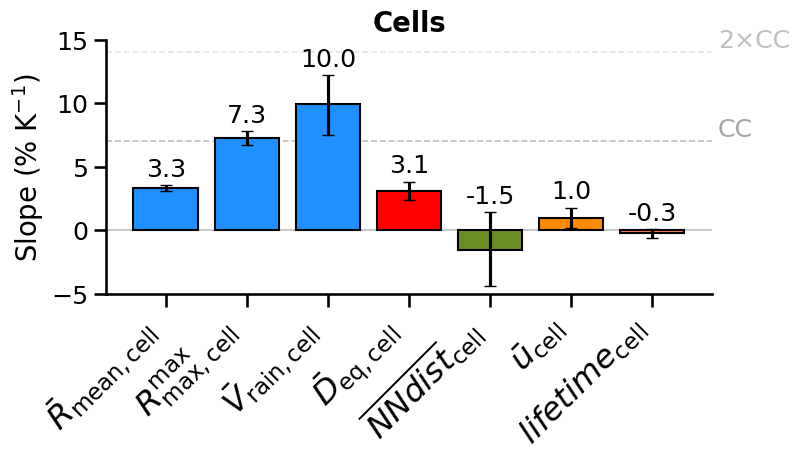

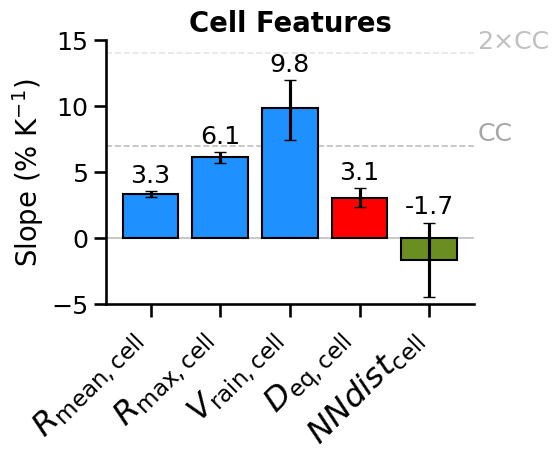

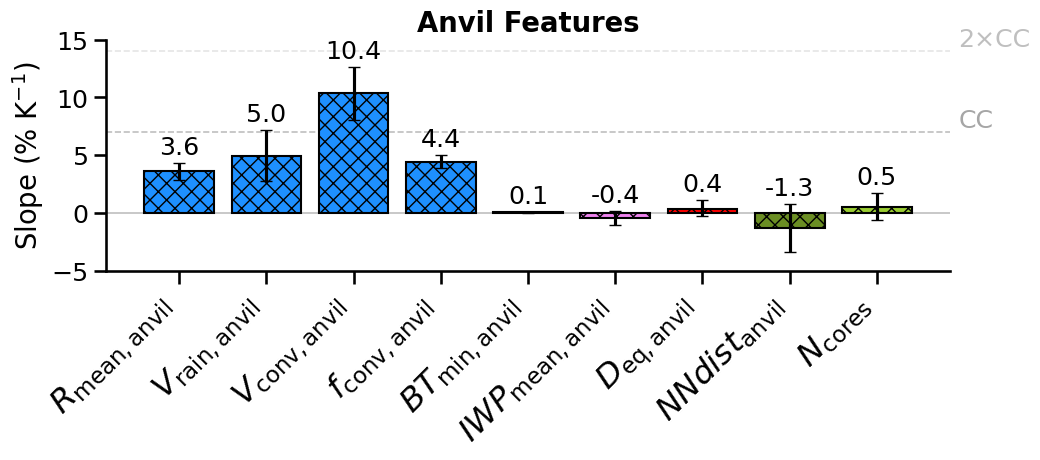

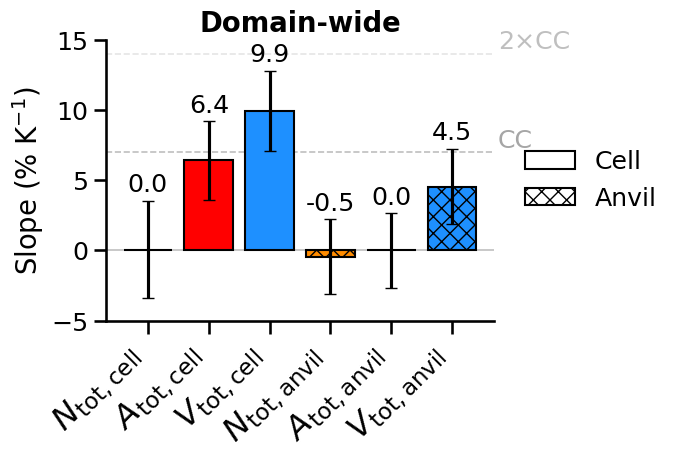

In [7]:
for dataset in datasets: 
    # select data
    dsplot = ds[dataset]

    # beauty stuff selection
    variables_to_plot = variable_order_map[dataset] #list(dsplot.variable.values)

    figwidth = len(variables_to_plot)*1.2
    
    source = "ICON"   # oder wie auch immer ihr das codiert
    VAR_META = defs_application.make_var_meta(variables_to_plot, source=source, get_hatch = True,
                                             base_hatches = base_hatches)
    if dataset == "domain":
        legendtype = "hatches" 
    else: 
        legendtype = None

    nice_title = dataset_title_map.get(dataset, dataset) 
    #'mean_daily_dens'
    fig = plots_figs.plot_slope_comparison(
        ds=dsplot,   
        variable_order=variables_to_plot,
        variant_order=['ALL'],
        VAR_META=VAR_META,             # variable metadata dict with 'label'
        #colors=colors,
        colortype= "variable",
        hatchtype = "variable",
        #hatches = basehatches,
        ylabel=r'Slope (% K$^{-1}$)',
        title = f"{nice_title}",
        ylim=(-5,15),
        figsize=(figwidth,5),
        output_path=os.path.join(output_directory,f"slopes_compare_per_T_{dataset}.pdf"),
        drawvalues = True, 
        legend = legendtype 
    )

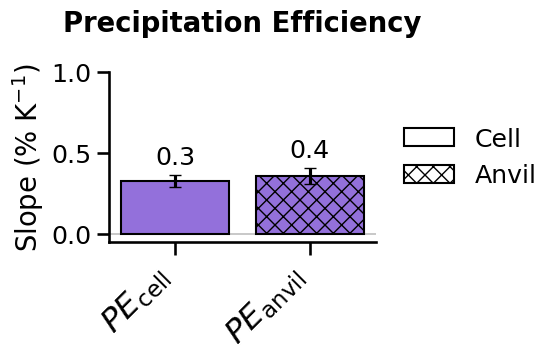

In [9]:
dataset = "cell_tracks"
# select data
dsplot = ds[dataset]

# beauty stuff selection
variables_to_plot = ["PE_cell","PE_anvil"]#list(dsplot.variable.values)

source = "ICON"   # oder wie auch immer ihr das codiert
VAR_META = defs_application.make_var_meta(variables_to_plot, source=source, get_hatch = True,
                                         base_hatches = base_hatches)

#'mean_daily_dens'
fig = plots_figs.plot_slope_comparison(
    ds=dsplot,   
    variable_order=variables_to_plot,
    variant_order=['ALL'],
    VAR_META=VAR_META,             # variable metadata dict with 'label'
    #colors=colors,
    colortype= "variable",
    hatchtype = "variable",
    #hatches = hatches,
    ylabel=r'Slope (% K$^{-1}$)',
    title = f"Precipitation Efficiency\n",
    ylim=(-0.05,1),
    figsize=(6,4),
    output_path=os.path.join(output_directory,"slopes_compare_per_T_PE.pdf"),
    showCClines = False,
    drawvalues = True,
    legend = "hatches",
    
)